In [ ]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

DATA_PATH = Path(os.environ.get("MELBOURNE_DATA", Path.cwd() / "Melbourne_housing_FULL.csv"))
if not DATA_PATH.exists():
    DATA_PATH = Path(r"C:\Users\Kate\Desktop\Унік\мага\sem_1\ляшкевич\Melbourne_housing_FULL.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}. Set MELBOURNE_DATA to its location.")

df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} rows and {df.shape[1]} columns from {DATA_PATH}")
display(df.head())
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "non_null": df.notna().sum(), "missing": df.isna().sum()}))

Loaded 34,857 rows and 21 columns from c:\Users\Kate\Desktop\Унік\мага\sem_1\ляшкевич\Melbourne_housing_FULL.csv


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,68 Studley St,2,h,NaN,SS,Jellis,3/09/2016,2.5,3067.0,...,1.0,1.0,126.0,NaN,NaN,Yarra City Council,-37.8014,144.9958,Northern Metropolitan,4019.0
1,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra City Council,-37.7996,144.9984,Northern Metropolitan,4019.0
2,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra City Council,-37.8079,144.9934,Northern Metropolitan,4019.0
3,Abbotsford,18/659 Victoria St,3,u,NaN,VB,Rounds,4/02/2016,2.5,3067.0,...,2.0,1.0,0.0,NaN,NaN,Yarra City Council,-37.8114,145.0116,Northern Metropolitan,4019.0
4,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra City Council,-37.8093,144.9944,Northern Metropolitan,4019.0


,dtype,non_null,missing
Suburb,object,34857,0
Address,object,34857,0
Rooms,int64,34857,0
Type,object,34857,0
Price,float64,27247,7610
Method,object,34857,0
SellerG,object,34857,0
Date,object,34857,0
Distance,float64,34856,1
Postcode,float64,34856,1


## 2. Профіль набору даних і пропуски
Функція `profile` показує тип, частку пропусків, унікальність, мінімум/максимум і п'ять найчастіших значень для кожного поля. Для текстових і датоподібних полів мінімум/максимум є лексикографічними або часовими орієнтирами, а не числовою оцінкою.

In [ ]:
def profile(data):
    rows = []
    for column in data.columns:
        series = data[column]
        non_null = series.dropna()
        try:
            minimum, maximum = non_null.min(), non_null.max()
        except (TypeError, ValueError):
            minimum, maximum = None, None
        top = series.value_counts(dropna=True).head(5).to_dict()
        rows.append({
            "column": column, "dtype": str(series.dtype),
            "missing_count": int(series.isna().sum()),
            "missing_share": float(series.isna().mean()),
            "unique_count": int(series.nunique(dropna=True)),
            "unique_share": float(series.nunique(dropna=True) / max(series.notna().sum(), 1)),
            "min": minimum, "max": maximum, "top_5": top,
        })
    return pd.DataFrame(rows).set_index("column")

raw_profile = profile(df)
display(raw_profile)
print(f"Exact duplicate rows: {df.duplicated().sum():,} ({df.duplicated().mean():.2%})")

,dtype,missing_count,missing_share,unique_count,unique_share,min,max,top_5
column,,,,,,,,
Suburb,object,0,0.000000,351,0.010070,Abbotsford,viewbank,"{'Reservoir': 844, 'Bentleigh East': 583, 'Ric..."
Address,object,0,0.000000,34009,0.975672,1 Abercrombie St,9b Stewart St,"{'5 Charles St': 6, '25 William St': 4, '16 Cl..."
Rooms,int64,0,0.000000,12,0.000344,1,16,"{3: 15084, 2: 8332, 4: 7956, 5: 1737, 1: 1479}"
Type,object,0,0.000000,3,0.000086,h,u,"{'h': 23980, 'u': 7297, 't': 3580}"
Price,float64,7610,0.218321,2871,0.105369,85000.0,11200000.0,"{600000.0: 235, 1100000.0: 235, 650000.0: 219,..."
Method,object,0,0.000000,9,0.000258,PI,W,"{'S': 19744, 'SP': 5095, 'PI': 4850, 'VB': 310..."
SellerG,object,0,0.000000,388,0.011131,@Realty,voglwalpole,"{'Jellis': 3359, 'Nelson': 3236, 'Barry': 3235..."
Date,object,0,0.000000,78,0.002238,1/07/2017,9/12/2017,"{'28/10/2017': 1119, '17/03/2018': 970, '24/02..."
Distance,float64,1,0.000029,215,0.006168,0.0,48.1,"{11.2: 1420, 13.8: 681, 9.2: 665, 7.8: 662, 10..."


Exact duplicate rows: 1 (0.00%)


### Пошук контекстних заглушок
Заглушки треба визначати за змістом поля. Наприклад, `0` може бути коректним для `Car`, а `1900` не є надійно підтвердженим роком будівництва. Код рахує кандидати до перетворення; числові -1/9999 та рік 1900 замінюються лише у визначених полях. Текстові `N/A` сприймаються pandas як пропуски під час читання CSV.

In [3]:
# Count placeholder candidates before cleaning, scoped to semantically relevant columns.
placeholder_counts = {}
for column in df.columns:
    series = df[column]
    count = int(series.astype(str).str.strip().str.upper().isin({"N/A", "NA", "NULL", "UNKNOWN"}).sum())
    if count:
        placeholder_counts[column] = count
for column in ["Price", "Rooms", "Bedroom2", "Bathroom", "Car", "Landsize", "BuildingArea", "YearBuilt", "Distance", "Postcode", "Propertycount"]:
    if column in df:
        numeric = pd.to_numeric(df[column], errors="coerce")
        count = int(numeric.isin([-1, 9999]).sum())
        if count:
            placeholder_counts[column] = placeholder_counts.get(column, 0) + count
        if column == "YearBuilt":
            count_1900 = int(numeric.eq(1900).sum())
            if count_1900:
                placeholder_counts[column] = placeholder_counts.get(column, 0) + count_1900
display(pd.Series(placeholder_counts, name="placeholder_candidates").to_frame())


,placeholder_candidates
YearBuilt,606


### Normalize placeholders

Convert only context-specific numeric placeholders to `NaN`, then profile the cleaned data again.

In [4]:
clean = df.copy()
for column in ["Price", "Rooms", "Bedroom2", "Bathroom", "Car", "Landsize", "BuildingArea", "YearBuilt", "Distance", "Postcode", "Propertycount"]:
    if column in clean:
        clean[column] = pd.to_numeric(clean[column], errors="coerce")
        clean.loc[clean[column].isin([-1, 9999]), column] = np.nan
if "YearBuilt" in clean:
    clean.loc[clean["YearBuilt"].eq(1900), "YearBuilt"] = np.nan

print("Missing values before/after contextual placeholder handling:")
display(pd.DataFrame({"before": df.isna().sum(), "after": clean.isna().sum(), "newly_missing": clean.isna().sum() - df.isna().sum()}))
clean_profile = profile(clean)
display(clean_profile[["dtype", "missing_count", "missing_share", "unique_count", "min", "max"]])

Missing values before/after contextual placeholder handling:


,before,after,newly_missing
Suburb,0,0,0
Address,0,0,0
Rooms,0,0,0
Type,0,0,0
Price,7610,7610,0
Method,0,0,0
SellerG,0,0,0
Date,0,0,0
Distance,1,1,0
Postcode,1,1,0


,dtype,missing_count,missing_share,unique_count,min,max
column,,,,,,
Suburb,object,0,0.000000,351,Abbotsford,viewbank
Address,object,0,0.000000,34009,1 Abercrombie St,9b Stewart St
Rooms,float64,0,0.000000,12,1.0,16.0
Type,object,0,0.000000,3,h,u
Price,float64,7610,0.218321,2871,85000.0,11200000.0
Method,object,0,0.000000,9,PI,W
SellerG,object,0,0.000000,388,@Realty,voglwalpole
Date,object,0,0.000000,78,1/07/2017,9/12/2017
Distance,float64,1,0.000029,215,0.0,48.1


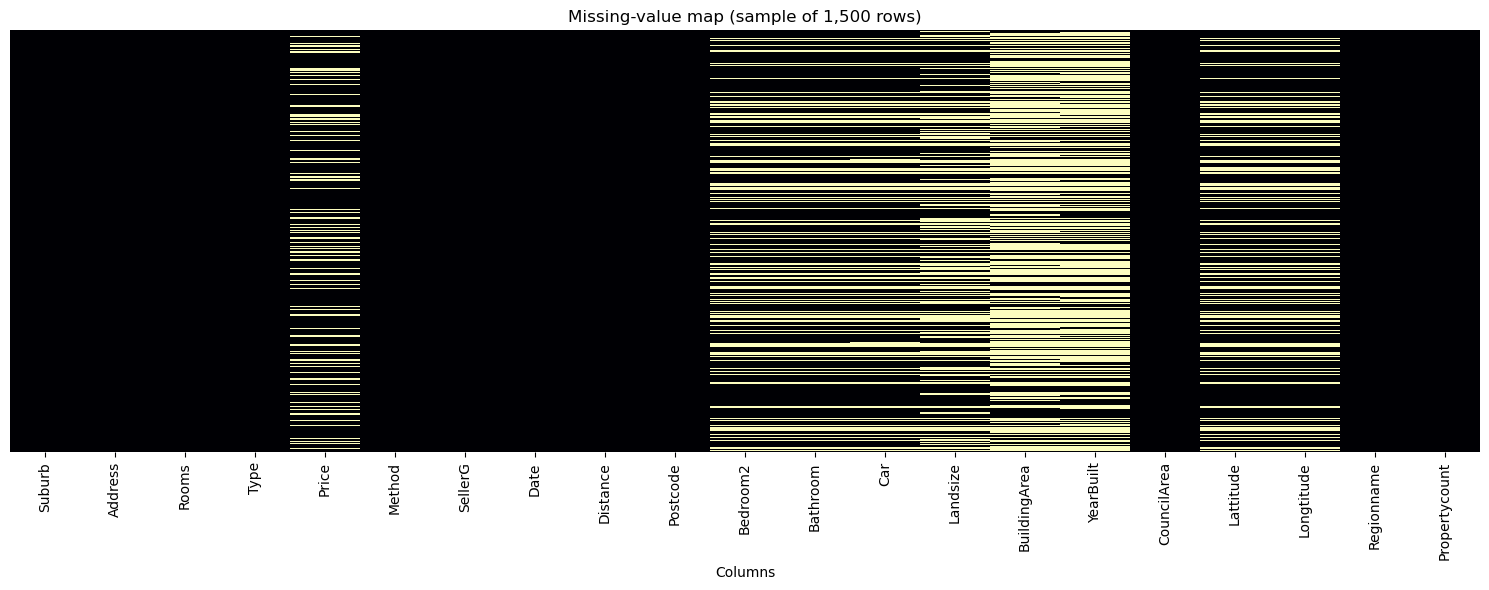

,missing_share
BuildingArea,0.605761
YearBuilt,0.571248
Landsize,0.338813
Car,0.250394
Bathroom,0.235993
Bedroom2,0.235735
Lattitude,0.228821
Longtitude,0.228821
Price,0.218321
Regionname,0.000086


Rows with at least one missing field: 75.46%


In [5]:
# Plot a readable missingness map for a deterministic sample of rows.
sample_size = min(1500, len(clean))
missing_sample = clean.sample(sample_size, random_state=42).isna()
plt.figure(figsize=(15, 6))
sns.heatmap(missing_sample, cbar=False, yticklabels=False, cmap="magma")
plt.title(f"Missing-value map (sample of {sample_size:,} rows)")
plt.xlabel("Columns")
plt.tight_layout()
plt.show()

missing_by_column = clean.isna().mean().sort_values(ascending=False)
display(missing_by_column.rename("missing_share").to_frame().head(10))
print("Rows with at least one missing field:", f"{clean.isna().any(axis=1).mean():.2%}")

## 3. Метрики якості за стовпцями та зрізами
Метрики повноти, кандидатної унікальності, доменної валідності, узгодженості та актуальності зводяться в єдину таблицю. Показник актуальності тут — частка дат не старших за один рік від найновішого спостереження; він не доводить актуальність щодо реального часу. Для зрізів використано регіон і рік події, оскільки джерело та дата завантаження у файлі відсутні.

In [6]:
# Parse dates explicitly because the source uses day/month/year strings.
if "Date" in clean:
    clean["Date_parsed"] = pd.to_datetime(clean["Date"], dayfirst=True, errors="coerce")

def share(mask, denominator=None):
    # Return a safe fraction for boolean masks.
    if denominator is None:
        denominator = len(mask)
    return float(mask.sum() / denominator) if denominator else np.nan

n = len(clean)
metrics = []
def add_metric(dimension, field, value, threshold, note=""):
    metrics.append({"dimension": dimension, "field": field, "value": value, "threshold": threshold, "status": "PASS" if pd.notna(value) and value >= threshold else "REVIEW", "note": note})

for column, threshold in [("Price", 0.80), ("Rooms", 0.99), ("Suburb", 0.99), ("BuildingArea", 0.50), ("YearBuilt", 0.50)]:
    if column in clean:
        add_metric("completeness", column, float(clean[column].notna().mean()), threshold)

key_columns = [c for c in ["Suburb", "Address", "Date", "Method"] if c in clean]
complete_key = clean[key_columns].notna().all(axis=1)
key_unique_share = float(1 - clean.loc[complete_key].duplicated(key_columns).mean()) if complete_key.any() else np.nan
add_metric("uniqueness", " + ".join(key_columns), key_unique_share, 0.98, "Candidate event key; duplicates need review")


### Validity, consistency, and timeliness

Check value domains, relationships between fields, and date age within the dataset.

In [7]:
if "Price" in clean:
    valid_price = clean["Price"].gt(0) & clean["Price"].notna()
    add_metric("validity", "Price > 0", share(valid_price, clean["Price"].notna().sum()), 0.99)
if "Rooms" in clean:
    valid_rooms = clean["Rooms"].between(1, 10)
    add_metric("validity", "Rooms in [1, 10]", share(valid_rooms, clean["Rooms"].notna().sum()), 0.99)
if "Type" in clean:
    valid_type = clean["Type"].isin(["h", "u", "t"])
    add_metric("validity", "Type in {h,u,t}", share(valid_type, clean["Type"].notna().sum()), 0.99)
if {"Bedroom2", "Rooms"}.issubset(clean.columns):
    checked = clean[["Bedroom2", "Rooms"]].notna().all(axis=1)
    consistent = clean["Bedroom2"].le(clean["Rooms"])
    add_metric("consistency", "Bedroom2 <= Rooms", share(consistent[checked], int(checked.sum())), 0.99, "Heuristic; source semantics may differ")
if {"Lattitude", "Longtitude"}.issubset(clean.columns):
    checked = clean[["Lattitude", "Longtitude"]].notna().all(axis=1)
    consistent = clean["Lattitude"].between(-39, -37) & clean["Longtitude"].between(144, 146)
    add_metric("consistency", "Melbourne coordinate bounds", share(consistent[checked], int(checked.sum())), 0.99)
if "Date_parsed" in clean and clean["Date_parsed"].notna().any():
    newest = clean["Date_parsed"].max()
    recent = clean["Date_parsed"].ge(newest - pd.Timedelta(days=365))
    add_metric("timeliness", "Date within 365 days of dataset maximum", share(recent[clean["Date_parsed"].notna()], int(clean["Date_parsed"].notna().sum())), 0.80, f"Reference date: {newest.date()}")


In [8]:
quality_metrics = pd.DataFrame(metrics)
display(quality_metrics)

,dimension,field,value,threshold,status,note
0,completeness,Price,0.781679,0.80,REVIEW,
1,completeness,Rooms,1.000000,0.99,PASS,
2,completeness,Suburb,1.000000,0.99,PASS,
3,completeness,BuildingArea,0.394239,0.50,REVIEW,
4,completeness,YearBuilt,0.428752,0.50,REVIEW,
5,uniqueness,Suburb + Address + Date + Method,0.999857,0.98,PASS,Candidate event key; duplicates need review
6,validity,Price > 0,1.000000,0.99,PASS,
7,validity,"Rooms in [1, 10]",0.999885,0.99,PASS,
8,validity,"Type in {h,u,t}",1.000000,0.99,PASS,
9,consistency,Bedroom2 <= Rooms,0.989527,0.99,REVIEW,Heuristic; source semantics may differ


In [9]:
# Compare price completeness and validity across region and event-year slices.
if "Regionname" in clean:
    region_quality = clean.groupby("Regionname", dropna=False).agg(
        rows=("Suburb", "size"),
        price_completeness=("Price", lambda s: s.notna().mean()),
        median_price=("Price", "median"),
    ).sort_values("price_completeness")
    display(region_quality)
    eligible = region_quality[region_quality["rows"] >= 100]
    print("Lowest completeness region with at least 100 rows:", eligible.index[0] if len(eligible) else "No eligible region")

if "Date_parsed" in clean and "Price" in clean:
    clean["event_year"] = clean["Date_parsed"].dt.year
    year_quality = clean.groupby("event_year", dropna=False).agg(
        rows=("Price", "size"),
        price_completeness=("Price", lambda s: s.notna().mean()),
    ).sort_index()
    display(year_quality)


,rows,price_completeness,median_price
Regionname,,,
Southern Metropolitan,11836,0.720176,1250000.0
Eastern Victoria,228,0.728070,679000.0
Eastern Metropolitan,4377,0.747544,1015000.0
South-Eastern Metropolitan,1739,0.771133,811250.0
Northern Victoria,203,0.817734,565000.0
Northern Metropolitan,9557,0.822852,752500.0
Western Victoria,115,0.834783,412125.0
Western Metropolitan,6799,0.855273,750000.0
NaN,3,1.000000,710000.0


Lowest completeness region with at least 100 rows: Southern Metropolitan


,rows,price_completeness
event_year,,
2016,10292,0.782550
2017,19852,0.781735
2018,4713,0.779546


### Slice comparison plots

The plots make local differences visible even when the overall missing-value rate looks acceptable.

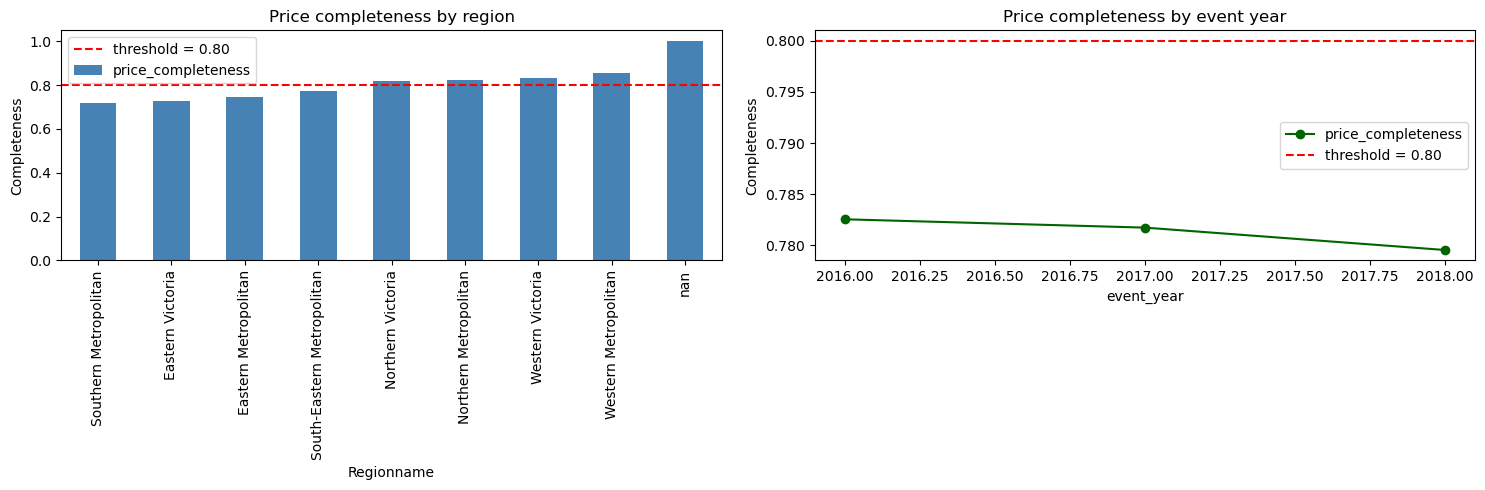

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
if "Regionname" in clean:
    region_quality["price_completeness"].plot(kind="bar", ax=axes[0], color="steelblue")
    axes[0].axhline(0.80, color="red", linestyle="--", label="threshold = 0.80")
    axes[0].set_title("Price completeness by region")
    axes[0].set_ylabel("Completeness")
    axes[0].legend()
if "Date_parsed" in clean and "Price" in clean:
    year_quality["price_completeness"].plot(ax=axes[1], marker="o", color="darkgreen")
    axes[1].axhline(0.80, color="red", linestyle="--", label="threshold = 0.80")
    axes[1].set_title("Price completeness by event year")
    axes[1].set_ylabel("Completeness")
    axes[1].legend()
plt.tight_layout()
plt.show()


In [11]:
# Report how far the worst sufficiently large region differs from the overall rate.
overall_price_completeness = clean["Price"].notna().mean()
if "Regionname" in clean and len(eligible):
    worst_region = eligible.index[0]
    gap_pp = (overall_price_completeness - eligible.loc[worst_region, "price_completeness"]) * 100
    print(f"Overall Price completeness: {overall_price_completeness:.2%}; {worst_region}: {eligible.loc[worst_region, 'price_completeness']:.2%} (gap {gap_pp:.1f} percentage points).")
    print("A global average can hide this local defect because better-performing regions offset missing prices in the weaker region.")

Overall Price completeness: 78.17%; Southern Metropolitan: 72.02% (gap 6.2 percentage points).
A global average can hide this local defect because better-performing regions offset missing prices in the weaker region.


## 4. Автоматизовані перевірки
Нижче реалізовано перевірки на рівні полів, записів і набору. `critical` означає блокування сценарію, що вимагає надійної цільової ціни/ідентичності подій; `warning` означає, що аналіз можна продовжити після перегляду звіту. Для кожного правила звіт містить кількість, частку та приклади рядків.

In [12]:
def build_check_report(data):
    # Collect row-level violations and summarize each rule with examples.
    checks = []
    def add(name, mask, severity, description):
        mask = pd.Series(mask, index=data.index).fillna(False).astype(bool)
        checks.append((name, mask, severity, description))
    n_rows = len(data)
    if "Price" in data:
        add("Price missing", data["Price"].isna(), "critical", "Target price is missing")
        add("Price non-positive", data["Price"].notna() & data["Price"].le(0), "critical", "Price must be positive")
        add("Price extreme", data["Price"].notna() & ~data["Price"].between(10_000, 20_000_000), "warning", "Review price outside broad AUD range")
    if "Rooms" in data:
        add("Rooms integer domain", data["Rooms"].notna() & (~data["Rooms"].mod(1).eq(0) | ~data["Rooms"].between(1, 10)), "warning", "Rooms must be an integer from 1 to 10")
    if "Type" in data:
        add("Type domain", data["Type"].notna() & ~data["Type"].isin(["h", "u", "t"]), "warning", "Unexpected property type")
    if "Suburb" in data:
        add("Suburb present", data["Suburb"].isna() | data["Suburb"].astype(str).str.strip().eq(""), "critical", "Suburb is required for geographic analysis")
    if "Date_parsed" in data:
        add("Date parseable", data["Date_parsed"].isna(), "warning", "Date is missing or cannot be parsed")
    if "BuildingArea" in data:
        add("BuildingArea positive", data["BuildingArea"].notna() & data["BuildingArea"].le(0), "warning", "Building area must be positive when supplied")
    if {"Bedroom2", "Rooms"}.issubset(data.columns):
        checked = data[["Bedroom2", "Rooms"]].notna().all(axis=1)
        add("Bedrooms consistent with rooms", checked & data["Bedroom2"].gt(data["Rooms"]), "warning", "Bedroom2 exceeds Rooms")
    if {"Lattitude", "Longtitude"}.issubset(data.columns):
        both = data[["Lattitude", "Longtitude"]].notna().all(axis=1)
        inside = data["Lattitude"].between(-39, -37) & data["Longtitude"].between(144, 146)
        add("Coordinates in Melbourne bounds", both & ~inside, "warning", "Coordinates fall outside broad Melbourne bounds")
    candidate_key = [c for c in ["Suburb", "Address", "Date", "Method"] if c in data]
    if candidate_key:
        key_complete = data[candidate_key].notna().all(axis=1)
        duplicated_key = data.loc[key_complete].duplicated(candidate_key, keep=False).reindex(data.index, fill_value=False)
        add("Candidate event key duplicate", duplicated_key, "warning", "Candidate key repeats; inspect before deduplication")
    add("Dataset minimum size", pd.Series(n_rows < 5000, index=data.index), "critical", "Dataset must contain at least 5,000 records")
    rows = []
    for name, violations, severity, description in checks:
        positions = np.flatnonzero(violations.to_numpy())[:3]
        examples = data.iloc[positions].head(3).to_dict(orient="records")
        count = int(violations.sum())
        rows.append({"rule": name, "level": "dataset" if name == "Dataset minimum size" else ("record" if "consistent" in name.lower() or "duplicate" in name.lower() else "field"),
                     "severity": severity, "violations": count, "share": count / max(n_rows, 1),
                     "description": description, "examples": examples})
    return pd.DataFrame(rows)

check_report = build_check_report(clean)
display(check_report.drop(columns="examples"))
display(check_report[["rule", "examples"]])
print("Critical rules with violations:", int(((check_report.severity == "critical") & (check_report.violations > 0)).sum()))
print("Pipeline policy: stop on any critical violation; warn and continue on warning violations after recording examples.")

,rule,level,severity,violations,share,description
0,Price missing,field,critical,7610,0.218321,Target price is missing
1,Price non-positive,field,critical,0,0.000000,Price must be positive
2,Price extreme,field,warning,0,0.000000,Review price outside broad AUD range
3,Rooms integer domain,field,warning,4,0.000115,Rooms must be an integer from 1 to 10
4,Type domain,field,warning,0,0.000000,Unexpected property type
5,Suburb present,field,critical,0,0.000000,Suburb is required for geographic analysis
6,Date parseable,field,warning,0,0.000000,Date is missing or cannot be parsed
7,BuildingArea positive,field,warning,76,0.002180,Building area must be positive when supplied
8,Bedrooms consistent with rooms,record,warning,279,0.008004,Bedroom2 exceeds Rooms
9,Coordinates in Melbourne bounds,field,warning,0,0.000000,Coordinates fall outside broad Melbourne bounds


,rule,examples
0,Price missing,"[{'Suburb': 'Abbotsford', 'Address': '68 Studl..."
1,Price non-positive,[]
2,Price extreme,[]
3,Rooms integer domain,"[{'Suburb': 'Preston', 'Address': '12 Lyonsvil..."
4,Type domain,[]
5,Suburb present,[]
6,Date parseable,[]
7,BuildingArea positive,"[{'Suburb': 'North Melbourne', 'Address': '19 ..."
8,Bedrooms consistent with rooms,"[{'Suburb': 'Abbotsford', 'Address': '53 Turne..."
9,Coordinates in Melbourne bounds,[]


Critical rules with violations: 1
Pipeline policy: stop on any critical violation; warn and continue on warning violations after recording examples.


## 5. Протокол спостережень і матриця якості
Контрольний список покриває розмір, повноту, повтори, домени, зв'язки полів, дати й регіональні зрізи. Таблиці нижче формуються з поточного запуску, тому числові результати не вигадуються наперед. Релевантність дефекту залежить від сценарію: відсутня ціна критична для регресії ціни, але може бути прийнятною для опису кількості оголошень.

In [13]:
# Build an observation log from the checks and a quality matrix from measured metrics.
observation_log = check_report.loc[check_report["violations"] > 0, ["rule", "severity", "violations", "share", "description", "examples"]].copy()
observation_log["relevance"] = observation_log["severity"].map({"critical": "critical", "warning": "substantial"})
display(observation_log)

quality_matrix = quality_metrics[["dimension", "field", "threshold", "value", "status", "note"]].copy()
quality_matrix["value"] = quality_matrix["value"].map(lambda value: f"{value:.2%}" if pd.notna(value) else "not available")
quality_matrix["threshold"] = quality_matrix["threshold"].map(lambda value: f"{value:.2%}")
display(quality_matrix)


,rule,severity,violations,share,description,examples,relevance
0,Price missing,critical,7610,0.218321,Target price is missing,"[{'Suburb': 'Abbotsford', 'Address': '68 Studl...",critical
3,Rooms integer domain,warning,4,0.000115,Rooms must be an integer from 1 to 10,"[{'Suburb': 'Preston', 'Address': '12 Lyonsvil...",substantial
7,BuildingArea positive,warning,76,0.002180,Building area must be positive when supplied,"[{'Suburb': 'North Melbourne', 'Address': '19 ...",substantial
8,Bedrooms consistent with rooms,warning,279,0.008004,Bedroom2 exceeds Rooms,"[{'Suburb': 'Abbotsford', 'Address': '53 Turne...",substantial
10,Candidate event key duplicate,warning,10,0.000287,Candidate key repeats; inspect before deduplic...,"[{'Suburb': 'Maidstone', 'Address': '3/29 Burn...",substantial


,dimension,field,threshold,value,status,note
0,completeness,Price,80.00%,78.17%,REVIEW,
1,completeness,Rooms,99.00%,100.00%,PASS,
2,completeness,Suburb,99.00%,100.00%,PASS,
3,completeness,BuildingArea,50.00%,39.42%,REVIEW,
4,completeness,YearBuilt,50.00%,42.88%,REVIEW,
5,uniqueness,Suburb + Address + Date + Method,98.00%,99.99%,PASS,Candidate event key; duplicates need review
6,validity,Price > 0,99.00%,100.00%,PASS,
7,validity,"Rooms in [1, 10]",99.00%,99.99%,PASS,
8,validity,"Type in {h,u,t}",99.00%,100.00%,PASS,
9,consistency,Bedroom2 <= Rooms,99.00%,98.95%,REVIEW,Heuristic; source semantics may differ


### Completed validation checklist

In [14]:
checklist = pd.DataFrame([
    ("Dataset size", "Minimum 5,000 rows rule", len(clean), "checked"),
    ("Column profile", "profile(df): type, missingness, uniqueness, range, top values", len(clean.columns), "checked"),
    ("Hidden missing values", "Contextual -1/9999/1900 and text token scan", int(sum(placeholder_counts.values())), "checked"),
    ("Missingness map", "Fixed-seed sample heatmap", sample_size, "checked"),
    ("Quality metrics", "Completeness, uniqueness, validity, consistency, timeliness", len(quality_metrics), "checked"),
    ("Slices", "Region and event-year comparisons", int(clean["Regionname"].nunique()) if "Regionname" in clean else 0, "checked"),
    ("Automated rules", "Field, record, and dataset checks", len(check_report), "checked"),
], columns=["item", "method", "sample_or_count", "status"])
display(checklist)


,item,method,sample_or_count,status
0,Dataset size,"Minimum 5,000 rows rule",34857,checked
1,Column profile,"profile(df): type, missingness, uniqueness, ra...",23,checked
2,Hidden missing values,Contextual -1/9999/1900 and text token scan,606,checked
3,Missingness map,Fixed-seed sample heatmap,1500,checked
4,Quality metrics,"Completeness, uniqueness, validity, consistenc...",12,checked
5,Slices,Region and event-year comparisons,8,checked
6,Automated rules,"Field, record, and dataset checks",12,checked


### Overall suitability conclusion

In [15]:
failed_metrics = quality_metrics[quality_metrics["status"] != "PASS"]
critical_violations = int(check_report.loc[check_report["severity"] == "critical", "violations"].sum())
if critical_violations == 0 and len(failed_metrics) == 0:
    conclusion = "Conditionally suitable for exploratory analysis and modeling after handling missing values and reviewing warnings."
else:
    conclusion = "Conditionally suitable only with documented restrictions; resolve critical target/identity issues before price modeling."
print("Conclusion:", conclusion)
print("Main likely limitations to discuss from the measured tables: missing fields, candidate-key duplicates, heuristic consistency rules, and unknown extraction date/source.")

Conclusion: Conditionally suitable only with documented restrictions; resolve critical target/identity issues before price modeling.
Main likely limitations to discuss from the measured tables: missing fields, candidate-key duplicates, heuristic consistency rules, and unknown extraction date/source.
